# Title

## Project Introduction - RENAME


In the context of initial value ordinary differential equations (ODEs), stability consists of two main components: *problem* stability and *numerical* stability. 

### *Problem* *Stability*

A problem is stable if a small perturbation to the initial condition elicits only a small change in the solution. As the independent variable approaches infinity for both the original and perturbed problem, the problem is stated to be *asymptotically stable* if the two solutions converge to each other.

As an illustration, take the model problem, a linear first order ODE known as the test equation: $$\frac{dy}{dt} = \lambda y,  t \in [0 , T]$$
$$ y(0) = y_0 $$

Now, take the model problem and add a small pertubation to the initial condition: $$\frac{dy_\delta}{dt} = \lambda y_\delta,  t \in [0 , T]$$
$$ y_\delta(0) = y_0 +\delta $$

The respective solutions to the model problem and perturbed model problem are $$y(t) = y_0 e^{\lambda t}$$ and $$y_\delta(t) = (y_0+\delta)e^{\lambda t}$$ 

We take the maginitude of the exponent portion. By Euler's formula, $\lambda = a+ bi$: $$e^{\lambda t} = e^{at} [\cos(bt)+i\sin(bt)]$$

The $[\cos(bt)+i\sin(bt)]$ always has magnitude equal to 1, so the real (Re) part of the exponential controls stability. There are three cases.

1. $Re(\lambda) \leq 0$: The exponential factor stays bounded, and the problem is stable. 
2. $Re(\lambda) < 0$: The model and perturbed model problem converge towards each other. Thus, the problem is asymptotically stable. 
3. $Re(\lambda) > 0$: the problem is unbounded and unstable.

Higher order linear ODEs can be reduced to the test equation, so the practicality of this analysis is not limited to the order of the ODE.
### *Numerical Stability*

For an arbitrary numerical method, it is said to be convergent, or in other words, the computed solution tends to the true solution as the stepsize (h) approaches 0, if and only if it satisfies *consistency* and *stability* conditions.

##### Consistency

Take the one-step methods as a general numerical scheme where the solution to the ODE at the next step is a function of the current independent variable iteration, current solution, and the stepsize:

$$y_{n+1} = \Psi(t_n,y_n,h)$$

Then, the *local error* is given as 

$$e_{n+1} = \Psi(t_n,y(t_n),h) - y(t_{n+1})$$

and the *global error* is given as 

$$E_{n}(h) = y_n - y(t_n).$$

*Consistency* pertains to the local error (the difference between the numerical scheme's solution and the exact solution), although the exact solution is not known. 


$\Psi$ is said to be consistent if $\forall x \geq 0$.\, $$\lim_{h\to 0} \frac{e_n(h)}{h}=0$$

Next, $\Psi = O(h^p)$ if $e_n = O(h^{p+1})$. $e_n$ is due to the truncation of higher order terms in the approximation during the current iteration, which are of $O(h^{p+1})$. Furthermore, $E_{n} = O(h^{p})$, since $E_{n} = N \cdot O(h^{p+1}) = \frac{1}{h} \cdot O(h^{p+1})$, where N is the number of steps taken. These relations show how consistency relates to global accuracy.

##### Stability

*Stability* analysis reveals the behavior of a solver in a regime where h is small enough for accuracy demonstrated in the consistency section, but also large enough for tractability and computational efficiency.

If a numerical method is stable for a certain range of $\lambda$ in a similar fashion to stability of the model problem, then it will be stable for the problem as well, meaning numerical errors will not grow as the solution is obtained.

Consider an asymptotically stable model problem (ie. $Re(\lambda) < 0$). An analysis can be performed to understand the regions of stability for a numerical method as a function of both h and $\lambda$.

Suppose $e_{n} \approx c \cdot \mu^{n}$, where c is the local truncation error introduced at a single step, and $\mu$ is the growth/amplication factor. We are particularly interested in determining for what h and $\lambda$, $\lvert \mu \rvert$ <1 (no growth in error).

Example analyses are shown below.

**Example: Explicit Euler Method**

$$y_{n+1} = y_{n} + hf(t_n,y_n), f(t_n,y_n) = \lambda y_n$$
$$e_{n+1} = e_{n} + h\lambda e_n$$
$$c\mu^{n+1} = c\mu^{n} + h\lambda c\mu^n$$

Divide by $\mu^{n}$ and c

$$\mu = 1+h\lambda $$
$$\lvert \mu \rvert<1$$

Thus, the region of stability for Explicit Euler's method is $-1 \lt 1+h\lambda \lt 1$.

**Example: Implicit Euler Method**
$$y_{n+1} = y_{n} + hf(t_{n+1},y_{n+1}), f(t_{n+1},y_{n+1}) = \lambda y_{n+1}$$
$$e_{n+1} = e_{n} + h\lambda e_{n+1}$$
$$c\mu^{n+1} = c\mu^{n} + h\lambda c\mu^{n+1}$$

Divide $\mu^{n}$ and c and rearrange for $\mu$

$$\mu = \frac{1}{1-h\lambda}$$
$$\lvert \mu \rvert<1$$

Thus, the region of stability for Implicit Euler's method is  $-1 \lt \frac{1}{1-h\lambda} \lt 1$. Evidently, for $Re(\lambda) \lt 0$, $\forall h$ the method is stable. T

**This is an example of an** *A-stable* **method. An A-stable method is stable for any h value. For these cases, choosing h is not limited by numerical stability and must consider accuracy as well as tractability and computational efficiency**

In summary, stability consists of both problem stability and numerical stability. Problem stability imposes that a problem is stable if a small perturbation to the initial condition elicits only a small change in the solution. Numerical stability consists of both numerical consistency and numerical stability, which state that the error approachs zero as the step size approaches zero and the error does not grow as the solution is obtained.

### *Stiffness*

Consider a vector of coupled first order linear ODEs: $$\frac{d\bar{y}}{dt} = A\bar{y}$$

Decouple the system by expressing A matrix with its eigenvalues $\Lambda$ (eigenvalues along the diagonal and zero everywhere else) and eigenvector, U:

$$A = U \Lambda U^{-1}$$

Substitute this definition of A back into the ODE system:

$$\frac{d\bar{y}}{dt} = U \Lambda U^{-1}\bar{y}$$
$$U^{-1}\frac{d\bar{y}}{dt} = \Lambda U^{-1}\bar{y}$$

Let $y = U^{-1}\bar{y}$ and obtain the redefined ODE system:

$$\frac{dy}{dt}=\Lambda y$$

Since $\Lambda$ is strictly diagonal, $\frac{dy}{dt}=\Lambda y$ produces completely decoupled equations. Integrating each row separately gives the solution for every component of y(t): $$y_i(t) = c_ie^{\lambda_{i}t}$$

**To obtain the solution to the original system**, the decoupled system must be re-coupled:

$$\bar{y} = Uy$$

The solution will be the column vector $\bar{y}$, where each column is a linear combination of the individual $y's$:

$$\bar{y} = c_1e^{\lambda_{1}t}\mathbf{u_1}+c_2e^{\lambda_{2}t}\mathbf{u_2}+ ... + c_ie^{\lambda_{i}t}u_i$$

,where $\mathbf{u}$ are the columns of U.

In the context of the system above, the eigenvalues of A determine the rate of decay for each component, assuming that the components of the solution follow the asympotically stable property of the model problem (ie. $Re(\lambda) \lt 0$). A problem is considered *stiff* if it contains widely varying time scales, and some components of the solution decay quicker than the others.

In fact, the stiffness ratio (S) is defined:

$$S = \frac{Re(\lvert \lambda_{\text{max}}\rvert)}{Re(\lvert \lambda_{\text{min}}\rvert)}$$

When $ S = 100, 10^4, 10^6$, the system of first order linear ODEs is considered mildly, moderately, and very stiff, respectively. For stiff problems, the choice of the numerical method and stepsize, h, must ensure numerical error does not propagate (ie. $\lvert \mu \rvert<1$).

For example, take explicit Euler's method:

$$\mu = 1+h\lambda $$
$$-1 \lt 1+h\lambda \lt 1$$

Suppose $\lambda_{\text{fast}} = -100$ is a decoupled mode of a coupled linear system $\bar{\mathbf{y}}' = A\bar{\mathbf{y}}$, and $h = 0.1$ is chosen naively. Even if the initial condition is $y_{\text{fast}}(0) = 0$ (while the slow mode is active), the solver operates in the coupled $\bar{\mathbf{y}}$ basis, where matrix-vector multiplication introduces floating-point rounding errors of $O(10^{-16})$ into the fast mode on the very first step. Because $|1 + h\lambda_{\text{fast}}| = |1 - 10| = 9$, that perturbation grows by a factor of $9$ at each iteration $n$. By step $n = 17$, the rounding error from machine precision alone has amplified by $9^{17} \approx 1.67 \cdot 10^{16}$, pushing the numerical error to $O(1)$ and leading to unbounded divergence of the numerical approximation.

Through this example, it is evident that for a stiff problem, both the numerical method and the step size $h$ must be chosen to ensure numerical stability across vastly different timescales, keeping round-off and truncation errors bounded while maintaining an accurate approximation of the true solution.


### Problem Stability, Numerical Stability, and Stiffness Applied to a Coupled ODE System: Continuosly Stirred Tank Reactors (CSTRs) in Series

Consider a system of two CSTRs in series. The ODE system describing the mole and energy balance equations are coupled because the output of the first CSTR is fed into the subsequent CSTR. The governing ODE equations are as follows:

#### Governing ODEs (isothermal, constant volume)

Reactions: $A \xrightarrow{k_1} B$, $\quad B + B \xrightarrow{k_2} C + B$, $\quad B + C \xrightarrow{k_3} A + C$ (1)

Only A is fed to CSTR 1, with feed concentration $C_{A0}$. CSTR 2 is fed by the outlet of CSTR 1. Here $F$ is the volumetric flow rate, $V_1$ and $V_2$ are the reactor volumes, and $C_{A1}, C_{B1}, C_{C1}$ and $C_{A2}, C_{B2}, C_{C2}$ are the concentrations in reactors 1 and 2.

**CSTR 1**

$$\frac{dC_{A1}}{dt} = \frac{F}{V_1}\left(C_{A0} - C_{A1}\right) - k_1 C_{A1} + k_3 C_{B1} C_{C1}$$

$$\frac{dC_{B1}}{dt} = -\frac{F}{V_1} C_{B1} + k_1 C_{A1} - k_2 C_{B1}^2 - k_3 C_{B1} C_{C1}$$

$$\frac{dC_{C1}}{dt} = -\frac{F}{V_1} C_{C1} + k_2 C_{B1}^2$$

**CSTR 2**

$$\frac{dC_{A2}}{dt} = \frac{F}{V_2}\left(C_{A1} - C_{A2}\right) - k_1 C_{A2} + k_3 C_{B2} C_{C2}$$

$$\frac{dC_{B2}}{dt} = \frac{F}{V_2}\left(C_{B1} - C_{B2}\right) + k_1 C_{A2} - k_2 C_{B2}^2 - k_3 C_{B2} C_{C2}$$

$$\frac{dC_{C2}}{dt} = \frac{F}{V_2}\left(C_{C1} - C_{C2}\right) + k_2 C_{B2}^2$$

**State vector:** $\mathbf{y} = [C_{A1},\, C_{B1},\, C_{C1},\, C_{A2},\, C_{B2},\, C_{C2}]$

The coupling between reactors is one-way. Reactor 2 depends on reactor 1 through the inlet terms $C_{A1}, C_{B1}, C_{C1}$, and reactor 1 does not depend on reactor 2. Within each reactor, the three species are coupled through the reaction terms.

### Stiffness in the CSTR in Series System

Stiffness in the system is introduced through the varying time scales in the rate constants. Rate constant values for $k_1$, $k_2$, $k_3$ used for analysis of numerical solvers are $0.04, 3 \cdot 10^7$, and $10^4$, respectively. A simple physical intution that can be drawn is that, the concentration of B is approximately steady-state as its associated reaction has a rate constant of $k_2$ which essetially consumes it immediately. This intuition is shown quantitatively in later analysis.

Stiffness can also introduce itself through varying $F$ and $V_i$. The model problem/test equation demonstrates that the stiffness is directly related to $\lambda$. In both governing ODEs for $C_{A1}$ and $C_{A2}$, the approximate lambda besides the rate constant is $\frac{F}{V_1}$ and $\frac{F}{V_2}$, respectively. For the simplified governing ODES, F is fixed. Thus, the volume of the reactors ($V_{i}$), is the parameter that ultimately influences stiffness alongside the rate constants.

## Nomenclature

| Symbol | Meaning | Units |
|---|---|---|
| $A, B, C$ | Chemical species | |
| $n = 1, 2$ | Reactor index | |
| $j = 1, 2, 3$ | Reaction index | |
| $t$ | Time | time |
| $C_{in}$ ($i = A,B,C$) | Concentration of species $i$ in reactor $n$ (also the outlet stream) | mol/vol |
| $C_{i0}$ | Concentration of species $i$ in the feed to CSTR 1 | mol/vol |
| $C_{i03}$ | Concentration of species $i$ in the fresh feed to CSTR 2 | mol/vol |
| $T_n$ | Temperature of reactor $n$ (also its outlet stream) | K |
| $T_0$ | Feed temperature to CSTR 1 | K |
| $T_{03}$ | Fresh feed temperature to CSTR 2 | K |
| $T_{c,n}$ | Coolant temperature for reactor $n$ | K |
| $V_n$ | Liquid volume in reactor $n$ | vol |
| $F_0$ | Volumetric feed flow into CSTR 1 | vol/time |
| $F_1$ | Outlet flow of CSTR 1, which is the inlet from CSTR 1 to CSTR 2 | vol/time |
| $F_2$ | Outlet flow of CSTR 2 | vol/time |
| $F_3$ | Fresh feed flow into CSTR 2 | vol/time |
| $k_{0,j}$ | Pre-exponential factor of reaction $j$ | units of $k_j$ |
| $E_j$ | Activation energy of reaction $j$ | energy/mol |
| $R$ | Gas constant | energy/(mol·K) |
| $k_j(T_n)$ | Arrhenius rate constant of reaction $j$ at temperature $T_n$ | depends on order |
| $\Delta H_j$ | Heat of reaction $j$ (negative if exothermic) | energy/mol |
| $C_{p,i}$ | Molar heat capacity of species $i$ | energy/(mol·K) |
| $\Gamma_s$ | Heat capacity per volume of stream or reactor contents $s$ | energy/(vol·K) |
| $h_i(T)$ | Molar enthalpy of species $i$ at temperature $T$ | energy/mol |
| $U_n$ | Overall heat transfer coefficient for reactor $n$ | energy/(time·area·K) |
| $A_{ex,n}$ | Heat exchange area of reactor $n$ | area |
| $Q_n$ | Rate of heat removal by cooling from reactor $n$ | energy/time |


## Methods and Results

We define the ODE system in python like such

In [1]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import matplotlib.cm as cm

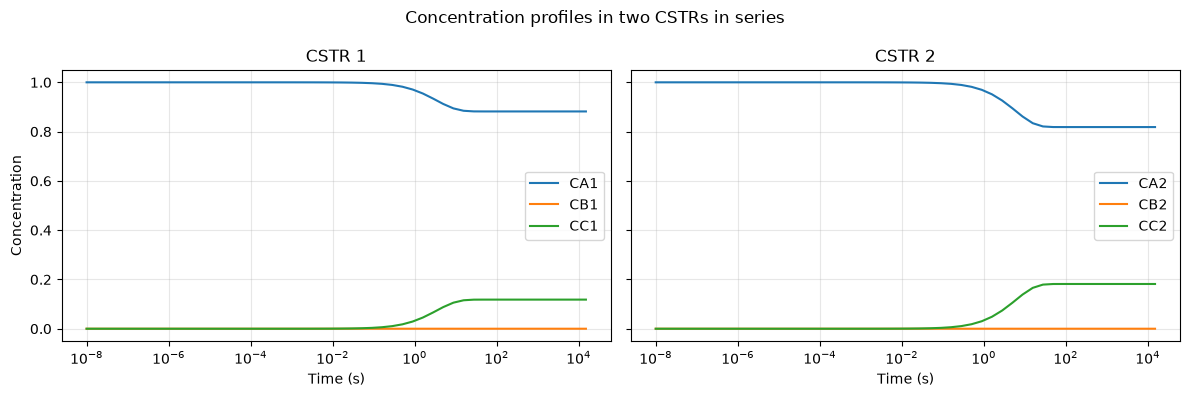

In [2]:
# Robertson-style kinetic parameters from above
k1 = 0.04       # 1/s
k2 = 3e7         # rate constant for B + B -> C + B
k3 = 1e4         # rate constant for B + C -> A + C

# Example operating conditions (edit these to match the system being modeled)
F = 1.0          # volumetric flow rate
V1 = 10.0        # reactor 1 volume
V2 = 10.0        # reactor 2 volume
CA0 = 1.0        # A concentration in the CSTR 1 feed

# Both reactors initially contain the feed composition; CSTR 2 receives CSTR 1's outlet.
Y0 = np.array([1.0, 0.0, 0.0])  # [CA, CB, CC]
y0_1 = Y0.copy()
y0_2 = Y0.copy()


def cstr1_odes(t, y, F, V1, CA0, k1, k2, k3):
    """Concentration balances for CSTR 1, with fresh A-only feed."""
    CA, CB, CC = y
    dilution = F / V1
    return [
        dilution * (CA0 - CA) - k1 * CA + k3 * CB * CC,
        -dilution * CB + k1 * CA - k2 * CB**2 - k3 * CB * CC,
        -dilution * CC + k2 * CB**2,
    ]


def cstr2_odes(t, y, F, V2, k1, k2, k3, cstr1_solution):
    """Concentration balances for CSTR 2, using CSTR 1's outlet as its feed."""
    CA, CB, CC = y
    CA1, CB1, CC1 = cstr1_solution.sol(t)
    dilution = F / V2
    return [
        dilution * (CA1 - CA) - k1 * CA + k3 * CB * CC,
        dilution * (CB1 - CB) + k1 * CA - k2 * CB**2 - k3 * CB * CC,
        dilution * (CC1 - CC) + k2 * CB**2,
    ]


# Log-spaced output resolves the fast transient as well as the slower evolution.
t_start, t_end = 0.0, 15000.0
t_eval = np.geomspace(1e-8, t_end)

solver_options = {
    "method": "Radau", 
    "t_eval": t_eval,
    "rtol": 1e-8,
    "atol": 1e-10,
    "dense_output": True,
}

solution_1 = solve_ivp(cstr1_odes, (t_start, t_end), y0_1, args=(F, V1, CA0, k1, k2, k3), **solver_options)
solution_2 = solve_ivp(cstr2_odes, (t_start, t_end), y0_2, args=(F, V2, k1, k2, k3, solution_1), **solver_options)

species = ["A", "B", "C"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for i, label in enumerate(species):
    axes[0].plot(solution_1.t, solution_1.y[i], label=f"C{label}1")
    axes[1].plot(solution_2.t, solution_2.y[i], label=f"C{label}2")

for ax, title in zip(axes, ["CSTR 1", "CSTR 2"]):
    ax.set_xscale("log")
    ax.set_xlabel("Time (s)")
    ax.set_title(title)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Concentration")
fig.suptitle("Concentration profiles in two CSTRs in series")
fig.tight_layout()
plt.show()

We're chosing two algorithms to solve this system of ODEs, RK45 and RADAU5. RADAU5 was chosen because it's known to be A-stable, a completely stable LHP, so stable for any step size. RK45 was chosen to contrast this, as explicit RK methods higher than order 2 are not A-stable. 

The above concentration profiles are the two CSTRs over time, solved with RADAU5. RK45 failed to converge, and we'll look at why below. From the concentration profiles, we can see that $C_A$, as the main reactant, decreases, $C_C$, as a terminal product, increases, and $C_B$ remains around $C_B \approx 0$, because the reaction rate $k_1$, which is creating species B is very slow, and the two reactions consuming species $ B $, $k_2, k_3$ are almost instant by comparison.

## Progress Since Proof of Concept

We did a stability analysis on exactly why RADAU5 converged (in ~1 second) and RK45 was still working after 725 minutes.

Following the derivation in these [lecture notes](https://jonshiach.github.io/ODEs-book/_pages/4.1_ERK_stability_function.html) from Manchester Metropolian University, the general equation for stability of RK methods is: $$R(z) = 1 + z\textbf{b}^T(I-z\textbf{A})^{-1}\textbf{e}$$ where $z=h\lambda$, $e=[1, 1, ..., 1]$, and $(A,b)$ come from the RK method butcher block. Using the butcher blocks for the two methods examined, RK45 & RADAU5, we're able to plot regions of absolute stability in the complex plane.

In [3]:
# ------------------------------------------------------------
# Dormand-Prince 5(4) (the method behind RK45), 7 stages (FSAL)
# ------------------------------------------------------------
c_dp = np.array([0, 1/5, 3/10, 4/5, 8/9, 1, 1])

A_dp = np.array([
    [0,            0,           0,           0,          0,            0,        0],
    [1/5,          0,           0,           0,          0,            0,        0],
    [3/40,         9/40,        0,           0,          0,            0,        0],
    [44/45,       -56/15,       32/9,        0,          0,            0,        0],
    [19372/6561,  -25360/2187,  64448/6561, -212/729,    0,            0,        0],
    [9017/3168,   -355/33,      46732/5247,  49/176,    -5103/18656,   0,        0],
    [35/384,       0,           500/1113,    125/192,   -2187/6784,    11/84,     0],
])

# 5th-order weights: propagated solution (equal to the last row of A, FSAL, so b[6] = 0)
b5_dp = np.array([35/384, 0, 500/1113, 125/192, -2187/6784, 11/84, 0])

# 4th-order weights: embedded solution, used only for error estimation
b4_dp = np.array([5179/57600, 0, 7571/16695, 393/640, -92097/339200, 187/2100, 1/40])

# ------------------------------------------------------------
# Radau IIA, 3 stages, order 5 (RADAU5)
# ------------------------------------------------------------
s6 = np.sqrt(6.0)

c_rad = np.array([(4 - s6)/10, (4 + s6)/10, 1.0])

A_rad = np.array([
    [(88 - 7*s6)/360,     (296 - 169*s6)/1800,  (-2 + 3*s6)/225],
    [(296 + 169*s6)/1800, (88 + 7*s6)/360,      (-2 - 3*s6)/225],
    [(16 - s6)/36,        (16 + s6)/36,          1/9],
])

b_rad = A_rad[-1].copy()   # stiffly accurate: b = last row of A

In [4]:
# ------------------------------------------------------------
# Stability eqn for RK methods
# ------------------------------------------------------------
def stability_R(A, b):
    """R(z) as a callable, via R = 1 + z b^T (I - zA)^{-1} 1 (works for explicit and implicit)."""
    s = len(b); one = np.ones(s); I = np.eye(s)
    def R(z):
        z = np.asarray(z, dtype=complex)
        out = np.empty(z.shape, dtype=complex)
        for idx, zi in np.ndenumerate(z):
            out[idx] = 1 + zi * (b @ np.linalg.solve(I - zi*A, one))
        return out
    return R

In [5]:
# ------------------------------------------------------------
# Stability eqn for RADAU5, RK4 and RK5
# ------------------------------------------------------------
R_dp5 = stability_R(A_dp, b5_dp)
R_dp4 = stability_R(A_dp, b4_dp)   # embedded method's stability function (not used for marching)
R_rad = stability_R(A_rad, b_rad)

In [6]:
def plot_stability_region(R, xlim=(-5, 2), ylim=(-4, 4), n=600, Title="title" ):
    x = np.linspace(*xlim, n)
    y = np.linspace(*ylim, n)
    X, Y = np.meshgrid(x, y)
    mag = np.abs(R(X + 1j * Y))

    plt.contourf(X, Y, mag, levels=[0, 1], colors="C0", alpha=0.35)
    plt.contour(X, Y, mag, levels=[1], colors="C0", linewidths=2)


    plt.xlabel("Re(z),  z = hλ")
    plt.ylabel("Im(z)")
    plt.title(f"Stability region |R(z)| ≤ 1 for {Title}") 
    plt.axhline(0, color="k", lw=0.6) 
    plt.axvline(0, color="k", lw=0.6)
    plt.grid(alpha=0.3)
    plt.show()
    

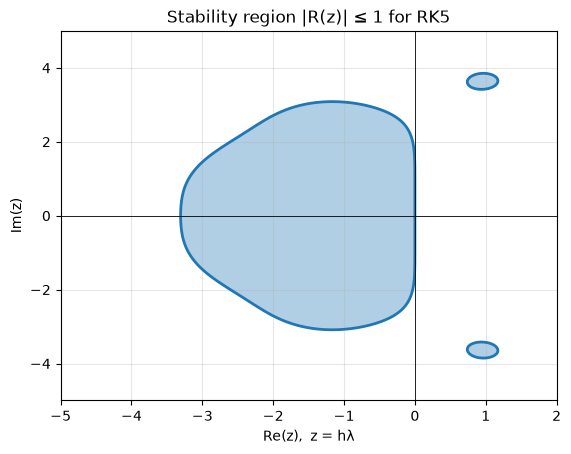

In [7]:
plot_stability_region(R_dp5, (-5, 2), (-5, 5), Title="RK5")

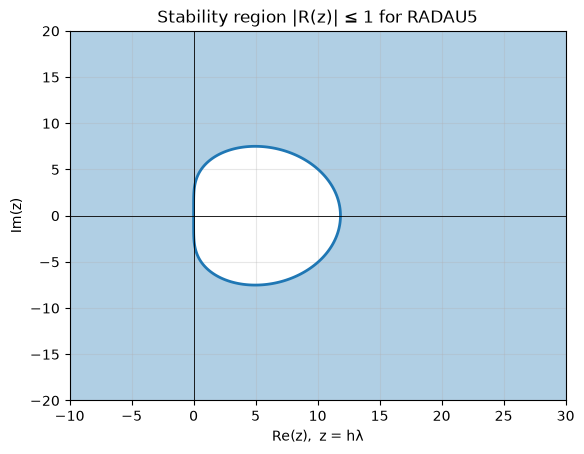

In [8]:
plot_stability_region(R_rad, (-10, 30), (-20, 20), Title="RADAU5")

This code can then be used to examine the stability of any RK methods

### Stability of Our ODE 

Analyzing only the behvaior of CSTR 1, we have our ODE equations given as

$$\frac{dC_{A1}}{dt} = \frac{F}{V_1}\left(C_{A0} - C_{A1}\right) - k_1 C_{A1} + k_3 C_{B1} C_{C1}$$

$$\frac{dC_{B1}}{dt} = -\frac{F}{V_1} C_{B1} + k_1 C_{A1} - k_2 C_{B1}^2 - k_3 C_{B1} C_{C1}$$

$$\frac{dC_{C1}}{dt} = -\frac{F}{V_1} C_{C1} + k_2 C_{B1}^2$$

We can write this as a matrix in the form of a state vector 

 $$ y = \begin{bmatrix}
    C_A \\
    C_B \\
    C_C 
\end{bmatrix} $$

and equations 

$$ f(y) = \begin{bmatrix}
    \frac{F}{V_1}\left(C_{A0} - C_{A1}\right) - k_1 C_{A1} + k_3 C_{B1} C_{C1} \\
    \frac{F}{V_1} C_{B1} + k_1 C_{A1} - k_2 C_{B1}^2 - k_3 C_{B1} C_{C1} \\
    \frac{F}{V_1} C_{C1} + k_2 C_{B1}^2
\end{bmatrix}$$

Then the jacobian looks like 

$$ J(f(y)) = \begin{bmatrix}
    \frac{F}{V}-k_1 & k_3C_{C1} & k_3C_B \\
    k_1 & -\frac{F}{V} - 2k_2C_B-k_3C_C & -k_3C_B \\ 
    0 & 2k_2C_B & -\frac{F}{V}
\end{bmatrix} 
$$

plugging in our constants $\frac{F}{V} = 0.1, k_1 = 0.04, k_2 = 3e7, k_3 = 1e4$ gives a jacobian as a function of our state that looks like 

$$\begin{bmatrix}
    -0.14 & 1*10^4C_C & 10^4C_B \\
    0.04 & -0.1-6*10^7C_B-10^4C_C & -10^4C_B \\
    0 & 6*10^7C_B & -0.1 
\end{bmatrix}$$

For our CSTR 1, with a tiny perturbation from the initial conditions of both reactors containing the feed composition, with $y_0 = \begin{bmatrix} 1.0 \\ 0.0 \\ 0.0 \end{bmatrix}$

In [9]:
def jacobian_cstr1(y, F, V, k1, k2, k3):
    CA, CB, CC = y

    d = F/V

    return np.array([
        [-d-k1,          k3*CC,                k3*CB],
        [k1,            -d-2*k2*CB-k3*CC,    -k3*CB],
        [0.0,            2*k2*CB,            -d]
    ])

In [10]:
# constants 
F = 1.0          # volumetric flow rate
V1 = 10.0        # reactor 1 volume
V2 = 10.0        # reactor 2 volume
CA0 = 1.0        # A concentration in the CSTR 1 feed
k1 = 0.04       # 1/s
k2 = 3e7         # rate constant for B + B -> C + B
k3 = 1e4         # rate constant for B + C -> A + C

# initial state in reactor 1, slightly perturbed
y = np.array([0.999, 0.001, 0.001]) 

J = jacobian_cstr1(y, F, V1, k1, k2, k3)

eigvals = np.linalg.eigvals(J)
eigvals

array([-6.00001e+04+0.j, -1.00000e-01+0.j, -1.01400e+01+0.j])

We need a step size h so that even the largest eigenvalue product is still in the region of stability, for RK45 it looks like $ |h\lambda| \le ~3.31$, and we have the real portion of our largest eigenvalue (since there's no oscilitory behavior) as $-6*10^4$, so our step size for RK45 limited by stability is $ h \le \frac{3.31}{6*10^4} \rightarrow h \le 5.5*10^{-5}$. 

The largest step size (at this state $ \textbf{Y} = \begin{bmatrix} 0.999 \\ 0.001 \\ 0.001 \end{bmatrix}$), limited by the stability of the system, largely constrained by the wide range in reaction rates $k_1, k_2, k_3$, is given by a step size $h = 5.5\times10^{-5}$

Comparitively, the step size of RADAU5 is not limited by stability as the stability plot shows that the entire LHP region is stable. This means that any selection of step size will still result in a stable system, and that step size is limited by accuracy instead of stability.

### Accuracy determination of step size

Since RK45 is a 5th order method, the error term is $O(\lambda h^6)$, and setting that equal to the allowed error tolerance for your algorithm, you get an accuracy limited step size as $(\lambda h)^6 = tol \rightarrow h = \frac{tol^{1/6}}{|\lambda|}$ 

In [11]:
lam_fast = np.max(np.abs(np.real(eigvals)))
lam_slow = np.min(np.abs(np.real(eigvals)))
tol = 10**-6

h_stability = 3.31 / lam_fast # upper bound of stability region for RK45 lies at around Re(z) = 3.31
h_accuracy = tol**(1/6) / lam_slow # tolerance^(1/6) due to error term for 5th order methods

print(f"The step size determined by accuracy for both methods is {h_accuracy:.5f}")
print(f"The step size determined by stability for RK45 is {h_stability:.6f}")


The step size determined by accuracy for both methods is 1.00000
The step size determined by stability for RK45 is 0.000055


And when plotting the step size as a function of the concentrations (to see when the stiffness becomes an issue) we can plot h as a function of $C_A, C_B, C_C$

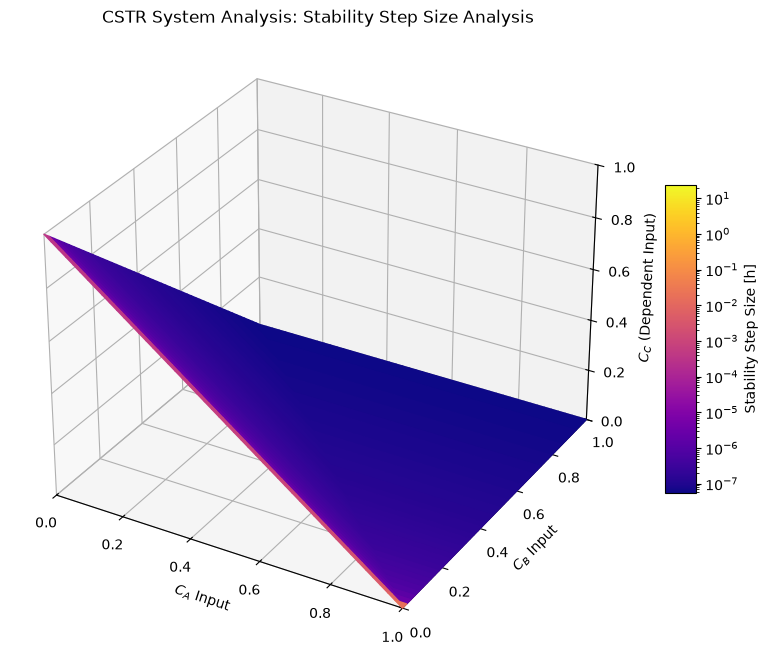

In [12]:
# view stability-determined step size of RK5 in a 3d plot in Y 
ca_range = np.linspace(0.0, 1.0, 50)
cb_range = np.linspace(0.0, 1.0, 50)
CA, CB = np.meshgrid(ca_range, cb_range)

CC = np.clip(1.0 - (CA + CB), 0.0, 1.0)

output_scalar = np.zeros_like(CA)

for i in range(CA.shape[0]):
    for j in range(CA.shape[1]):
        # Pack the specific coordinate inputs into the state vector 'y'
        y = np.array([CA[i, j], CB[i, j], CC[i, j]])

        J = jacobian_cstr1(y, F, V1, k1, k2, k3)

        eigvals = np.linalg.eigvals(J)

        lam_fast = np.max(np.abs(np.real(eigvals)))

        h_stability = 3.31 / lam_fast 

        output_scalar[i, j] = h_stability

from matplotlib.colors import LogNorm

norm = LogNorm(vmin=output_scalar.min(), vmax=output_scalar.max())
colors = cm.plasma(norm(output_scalar))

# Use the same norm for the colorbar
mappable = cm.ScalarMappable(cmap=cm.plasma, norm=norm)
mappable.set_array(output_scalar)


# 5. Build and format the 3D surface plot
fig, ax = plt.subplots(subplot_kw={"projection": "3d"}, figsize=(10, 8))

# Plot spatially by CA and CB, using the CC values for Z altitude height
# The colors matrix maps the Jacobian output directly onto the surface mesh
surf = ax.plot_surface(CA, CB, CC, facecolors=colors, shade=False)

# Explicitly constrain axes to go from 0 to 1
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_zlim(0, 1)

# Axis configuration labels
ax.set_xlabel("$C_A$ Input")
ax.set_ylabel("$C_B$ Input")
ax.set_zlabel("$C_C$ (Dependent Input)")
ax.set_title("CSTR System Analysis: Stability Step Size Analysis")

# 6. Construct colorbar to translate colors back to scalar output values
fig.colorbar(mappable, ax=ax, shrink=0.5, aspect=10, label="Stability Step Size [h]")

plt.show()

We can see that the stiffness of the system is mostly dependent on the $C_B$ reaction rate $k_2 = 3\times10^7$, and only when $C_B \approx 0$ is the stability step size approaching the accuracy step size

## Next Steps

- Steady state approx for $C_B$
- Plot the RK45 step size over the solutuon provided by RADAU5 to show why RK45 fails as step size gets increasingly worse 
- Benchmark different solvers (RK45, RADAU5, probably 2 more - Implicit RK, LMS?)
- Investigate how different stiffness ratios (from rxn rates) impact time to solve for different solvers (and then look into why the different algorithms might take longer)
- Physical/Engineering sensemaking: why does this matter
- Analyze how changing the physical system changes the stiffness of the problems (stiffness depends on F & V), 3 cases:
    - make F/V larger for first reactor
    - keep F/V equal for both reactors
    - make F/V smaller for first reactor

## Statements of Contributions

Nick worked on the introduction, which focused on laying down the foundation of IVP ODEs, their problem stability, numerical stability, and how these considerations tie into stiffness. Nick also connected stiffness to the reactor system that is to be modeled.

Charles worked on the methods and results, and the stability analysis of the algorithms. 

## References

(1) Mazzia, F.; Iavernaro, F. Test Set for Initial Value Problem Solvers. 2003.

(2) 4.2. Stability Functions — Runge-Kutta Methods. https://jonshiach.github.io/ODEs-book/_pages/4.1_ERK_stability_function.html (accessed 2026-11-09)

(3) 4.5. A-stability — Runge-Kutta Methods. https://jonshiach.github.io/ODEs-book/_pages/4.4_A_stability.html (accessed 2026-11-09)

(4) Dormand–Prince Method. Wikipedia; 2026.

(5) Fronk, C.; Petzold, L. Training Stiff Neural Ordinary Differential Equations with Implicit Single-Step Methods. Chaos: An Interdisciplinary Journal of Nonlinear Science 2024, 34 (12), 123147. https://doi.org/10.1063/5.0243382